<a href="https://colab.research.google.com/github/612202500232Pegy/Latihan-Naive-Bayes/blob/main/F12_2025_00232RPL_PEGY%20VERDIANTI_UTS_Penambangan_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS Penambangan Data (Praktek) — Ganjil 2026/2027
**Klasifikasi Tingkat Risiko Banjir untuk Sistem Informasi Mitigasi Bencana BPBD Kota Kediri**

Nama: PEGY VERDIANTI · NIM: F12.2025.00232 · Kelas: F12.D302RPL


- **Soal 01** — Data Collecting dan Data Preprocessing (rancangan CRISP-DM dijelaskan pada laporan PDF)
- **Soal 02** — Pembagian data latih/uji dan pelatihan model klasifikasi Naïve Bayes

**Masalah bisnis:** BPBD perlu menetapkan wilayah/kondisi mana yang berisiko banjir *tinggi* agar sumber daya mitigasi
(peringatan dini, logistik, evakuasi) diprioritaskan lebih dulu. Targetnya adalah kelas `Tinggi` vs `Rendah`.

## 0. Persiapan lingkungan

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
FIG_DIR = "figs"
os.makedirs(FIG_DIR, exist_ok=True)

BIRU, ORANYE, ABU = "#2F6DB5", "#D9822B", "#6B7280"
plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "serif", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.grid": True, "grid.color": "#E5E7EB", "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})
print("Siap. Versi pandas:", pd.__version__)

Siap. Versi pandas: 2.2.3


## 1. Data Collecting
Dataset: **Flood Prediction** — 50.000 observasi, 20 faktor penyebab/kerentanan banjir (skor ordinal bilangan bulat)
dan satu variabel `FloodProbability`

In [2]:
URLS = [
    "https://raw.githubusercontent.com/ayushxlxs/Flood-Risk-Visualisation-Analysis/main/flood.csv",
    "https://raw.githubusercontent.com/devawais01/flood-prediction-app/main/backend/dataset/flood.csv",
]

df_raw = None
for url in URLS:
    try:
        df_raw = pd.read_csv(url)
        print("Berhasil membaca data dari:", url)
        break
    except Exception as e:
        print("Gagal:", url, "->", e)

if df_raw is None:
    # Cadangan: unggah manual flood.csv (Colab)
    from google.colab import files
    up = files.upload()
    df_raw = pd.read_csv(next(iter(up)))

print("Ukuran data (baris, kolom):", df_raw.shape)
df_raw.head()

Berhasil membaca data dari: https://raw.githubusercontent.com/ayushxlxs/Flood-Risk-Visualisation-Analysis/main/flood.csv
Ukuran data (baris, kolom): (50000, 21)


,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,3,8,6,6,4,4,6,2,3,2,...,10,7,4,2,3,4,3,2,6,0.450
1,8,4,5,7,7,9,1,5,5,4,...,9,2,6,2,1,1,9,1,3,0.475
2,3,10,4,1,7,5,4,7,4,9,...,7,4,4,8,6,1,8,3,6,0.515
3,4,4,2,7,3,4,1,4,6,4,...,4,2,6,6,8,8,6,6,10,0.520
4,3,7,5,2,5,8,5,2,7,5,...,7,6,5,3,3,4,4,3,4,0.475


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   MonsoonIntensity                 50000 non-null  int64  
 1   TopographyDrainage               50000 non-null  int64  
 2   RiverManagement                  50000 non-null  int64  
 3   Deforestation                    50000 non-null  int64  
 4   Urbanization                     50000 non-null  int64  
 5   ClimateChange                    50000 non-null  int64  
 6   DamsQuality                      50000 non-null  int64  
 7   Siltation                        50000 non-null  int64  
 8   AgriculturalPractices            50000 non-null  int64  
 9   Encroachments                    50000 non-null  int64  
 10  IneffectiveDisasterPreparedness  50000 non-null  int64  
 11  DrainageSystems                  50000 non-null  int64  
 12  CoastalVulnerabili

In [4]:
df_raw.describe().T[["min", "max", "mean", "std"]].round(2)

,min,max,mean,std
MonsoonIntensity,0.00,16.00,4.99,2.24
TopographyDrainage,0.00,18.00,4.98,2.25
RiverManagement,0.00,16.00,5.02,2.23
Deforestation,0.00,17.00,5.01,2.22
Urbanization,0.00,17.00,4.99,2.24
ClimateChange,0.00,17.00,4.99,2.23
DamsQuality,0.00,16.00,5.02,2.24
Siltation,0.00,16.00,4.99,2.23
AgriculturalPractices,0.00,16.00,5.01,2.23
Encroachments,0.00,18.00,5.01,2.24


### 1.1 Data (EDA singkat)
Distribusi target `FloodProbability` dan korelasi tiap faktor terhadap target.

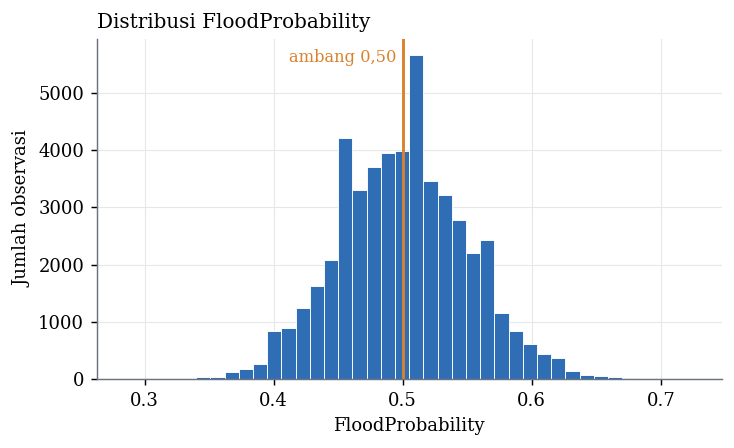

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.hist(df_raw["FloodProbability"], bins=40, color=BIRU, edgecolor="white", linewidth=0.5)
ax.axvline(0.50, color=ORANYE, lw=1.6)
ax.text(0.495, ax.get_ylim()[1]*0.97, "ambang 0,50", color=ORANYE, fontsize=9, va="top", ha="right")
ax.set_xlabel("FloodProbability"); ax.set_ylabel("Jumlah observasi")
ax.set_title("Distribusi FloodProbability", loc="left", fontsize=11)
fig.savefig(f"{FIG_DIR}/01_distribusi_target.png"); plt.show()

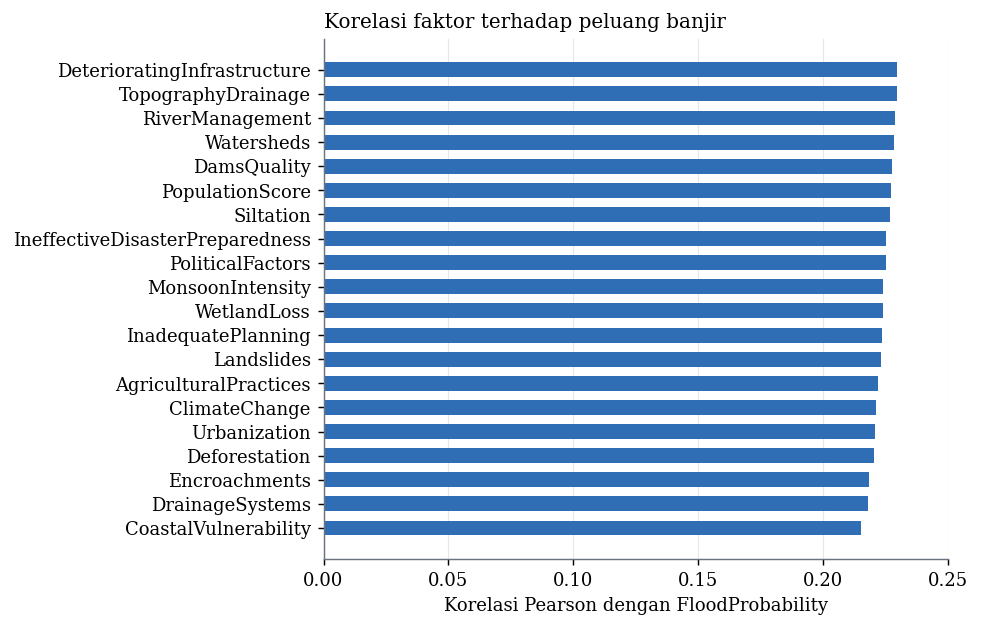

Rentang korelasi: 0.215 - 0.229


In [6]:
korelasi = (df_raw.drop(columns="FloodProbability")
            .corrwith(df_raw["FloodProbability"]).sort_values())
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.barh(korelasi.index, korelasi.values, color=BIRU, height=0.62)
ax.set_xlim(0, 0.25)
ax.set_xlabel("Korelasi Pearson dengan FloodProbability")
ax.set_title("Korelasi faktor terhadap peluang banjir", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(f"{FIG_DIR}/02_korelasi_fitur.png"); plt.show()
print("Rentang korelasi:", round(korelasi.min(), 3), "-", round(korelasi.max(), 3))

## 2. Data Preprocessing
Tahapan: (1) validasi struktur, (2) nilai hilang, (3) duplikat, (4) pencilan, (5) pembentukan label kelas,
(6) pemisahan fitur & target (mencegah *data leakage*), (7) cek ketergantungan antarfitur, (8) simpan data bersih.

In [7]:
df = df_raw.copy()

# (1) Validasi struktur
fitur_diharapkan = 20
assert df.shape[1] == fitur_diharapkan + 1, "Jumlah kolom tidak sesuai"
assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes), "Ada kolom non-numerik"
assert df["FloodProbability"].between(0, 1).all(), "FloodProbability di luar 0-1"
fitur = [c for c in df.columns if c != "FloodProbability"]
print("Validasi struktur lolos:", len(fitur), "fitur numerik.")
print("Rentang nilai fitur:", int(df[fitur].min().min()), "sampai", int(df[fitur].max().max()))

Validasi struktur lolos: 20 fitur numerik.
Rentang nilai fitur: 0 sampai 22


In [8]:
# (2) Nilai hilang
n_missing = int(df.isna().sum().sum())
print("Total nilai hilang:", n_missing)
if n_missing > 0:
    df[fitur] = df[fitur].fillna(df[fitur].median())   # imputasi median (tidak terpakai bila 0)

# (3) Duplikat
n_dup = int(df.duplicated().sum())
print("Baris duplikat:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran setelah pembersihan:", df.shape)

Total nilai hilang: 0
Baris duplikat: 0
Ukuran setelah pembersihan: (50000, 21)


In [9]:
# (4) Pencilan dengan aturan IQR (hanya dilaporkan, tidak dihapus)
q1, q3 = df[fitur].quantile(0.25), df[fitur].quantile(0.75)
iqr = q3 - q1
batas_bawah, batas_atas = q1 - 1.5*iqr, q3 + 1.5*iqr
jml_outlier = ((df[fitur] < batas_bawah) | (df[fitur] > batas_atas)).sum()
tabel_outlier = pd.DataFrame({"batas_bawah": batas_bawah, "batas_atas": batas_atas,
                              "jumlah_outlier": jml_outlier})
baris_outlier = ((df[fitur] < batas_bawah) | (df[fitur] > batas_atas)).any(axis=1).sum()
print(f"Baris dengan >=1 nilai di luar batas IQR: {baris_outlier} dari {len(df)} "
      f"({baris_outlier/len(df):.1%})")
tabel_outlier[tabel_outlier.jumlah_outlier > 0]

Baris dengan >=1 nilai di luar batas IQR: 12107 dari 50000 (24.2%)


,batas_bawah,batas_atas,jumlah_outlier
MonsoonIntensity,-1.5,10.5,686
TopographyDrainage,-1.5,10.5,711
RiverManagement,-1.5,10.5,661
Deforestation,-1.5,10.5,682
Urbanization,-1.5,10.5,687
ClimateChange,-1.5,10.5,647
DamsQuality,-1.5,10.5,741
Siltation,-1.5,10.5,671
AgriculturalPractices,-1.5,10.5,683
Encroachments,-1.5,10.5,688


Kelas_Risiko
Rendah    24487
Tinggi    25513
Kelas_Risiko
Rendah    0.49
Tinggi    0.51


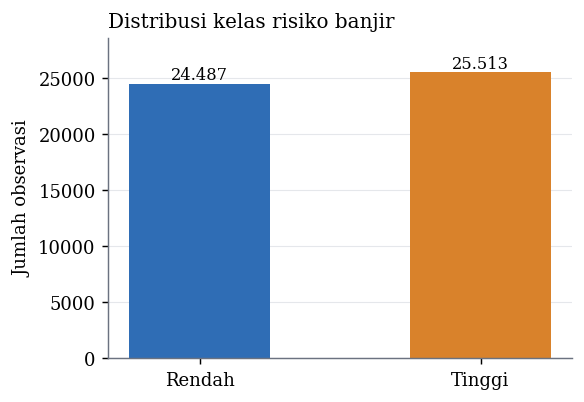

In [10]:
# (5) Pembentukan label klasifikasi dari FloodProbability
AMBANG = 0.50
df["Kelas_Risiko"] = (df["FloodProbability"] >= AMBANG).astype(int)   # 1 = Tinggi, 0 = Rendah
nama_kelas = {0: "Rendah", 1: "Tinggi"}
distribusi = df["Kelas_Risiko"].map(nama_kelas).value_counts().reindex(["Rendah", "Tinggi"])
print(distribusi.to_string())
print((distribusi / len(df)).round(3).to_string())

fig, ax = plt.subplots(figsize=(4.6, 3.2))
bars = ax.bar(distribusi.index, distribusi.values, color=[BIRU, ORANYE], width=0.5)
for b, v in zip(bars, distribusi.values):
    ax.text(b.get_x()+b.get_width()/2, v + len(df)*0.008, f"{v:,}".replace(",", "."), ha="center", fontsize=9)
ax.set_ylabel("Jumlah observasi"); ax.set_ylim(0, distribusi.max()*1.12)
ax.set_title("Distribusi kelas risiko banjir", loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
fig.savefig(f"{FIG_DIR}/03_distribusi_kelas.png"); plt.show()

In [11]:
# (6) Pisahkan fitur (X) dan target (y). FloodProbability DIBUANG dari X karena label diturunkan darinya.
X = df[fitur].copy()
y = df["Kelas_Risiko"].copy()
assert "FloodProbability" not in X.columns and "Kelas_Risiko" not in X.columns
print("X:", X.shape, "| y:", y.shape)

# (7) Cek ketergantungan antarfitur (asumsi independensi Naive Bayes)
kor = X.corr().abs().to_numpy(copy=True)
np.fill_diagonal(kor, 0)
print("Korelasi antarfitur terbesar (mutlak):", kor.max().round(3))

# (8) Simpan dataset bersih
df_bersih = pd.concat([X, y], axis=1)
df_bersih.to_csv("flood_bersih.csv", index=False)
print("Disimpan: flood_bersih.csv", df_bersih.shape)
df_bersih.head()

X: (50000, 20) | y: (50000,)
Korelasi antarfitur terbesar (mutlak): 0.013
Disimpan: flood_bersih.csv (50000, 21)


,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,Kelas_Risiko
0,3,8,6,6,4,4,6,2,3,2,...,10,7,4,2,3,4,3,2,6,0
1,8,4,5,7,7,9,1,5,5,4,...,9,2,6,2,1,1,9,1,3,0
2,3,10,4,1,7,5,4,7,4,9,...,7,4,4,8,6,1,8,3,6,1
3,4,4,2,7,3,4,1,4,6,4,...,4,2,6,6,8,8,6,6,10,1
4,3,7,5,2,5,8,5,2,7,5,...,7,6,5,3,3,4,4,3,4,0


## 3. Soal 02 — Pembagian data & pelatihan Naïve Bayes
**Pembagian data:** 80% latih, 20% uji, `stratify=y` agar proporsi kelas sama di kedua bagian, `random_state=42` agar hasil dapat diulang.
**Algoritma:** Gaussian Naïve Bayes (fitur numerik).

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Data latih :", X_train.shape, "| Data uji:", X_test.shape)
ringkas = pd.DataFrame({
    "latih": y_train.value_counts(normalize=True).sort_index(),
    "uji": y_test.value_counts(normalize=True).sort_index()}).round(3)
ringkas.index = ["Rendah", "Tinggi"]
ringkas

Data latih : (40000, 20) | Data uji: (10000, 20)


,latih,uji
Rendah,0.49,0.49
Tinggi,0.51,0.51


In [13]:
model = GaussianNB()
model.fit(X_train, y_train)

print("Prior kelas  [Rendah, Tinggi]:", model.class_prior_.round(4))
rata = pd.DataFrame(model.theta_, index=["Rendah", "Tinggi"], columns=fitur).T
rata["selisih"] = rata["Tinggi"] - rata["Rendah"]
rata.round(2).sort_values("selisih", ascending=False).head(5)

Prior kelas  [Rendah, Tinggi]: [0.4898 0.5102]


,Rendah,Tinggi,selisih
Watersheds,4.55,5.38,0.84
Siltation,4.56,5.39,0.83
IneffectiveDisasterPreparedness,4.59,5.42,0.83
DamsQuality,4.60,5.41,0.82
DeterioratingInfrastructure,4.58,5.38,0.81


### 3.1 Evaluasi model dan pengecekan overfitting

In [14]:
y_pred_train = model.predict(X_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

hasil = {
    "acc_train": accuracy_score(y_train, y_pred_train),
    "acc_test": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "auc": roc_auc_score(y_test, y_prob),
}
for k, v in hasil.items():
    print(f"{k:10s}: {v:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=["Rendah", "Tinggi"], digits=4))

acc_train : 0.9139
acc_test  : 0.9149
precision : 0.9152
recall    : 0.9183
f1        : 0.9168
auc       : 0.9771

              precision    recall  f1-score   support

      Rendah     0.9145    0.9114    0.9130      4897
      Tinggi     0.9152    0.9183    0.9168      5103

    accuracy                         0.9149     10000
   macro avg     0.9149    0.9148    0.9149     10000
weighted avg     0.9149    0.9149    0.9149     10000



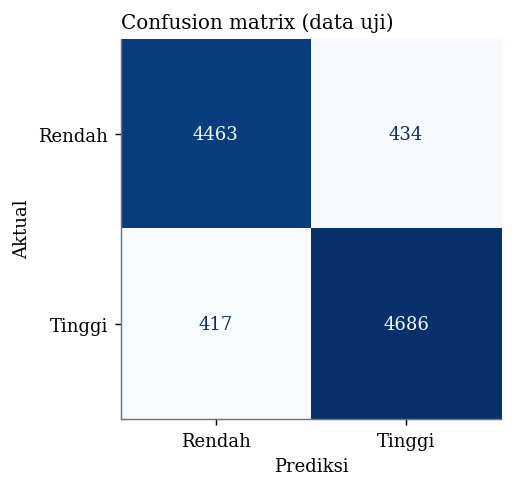

TN=4463  FP=434  FN=417  TP=4686


In [15]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ConfusionMatrixDisplay(cm, display_labels=["Rendah", "Tinggi"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.grid(False); ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
ax.set_title("Confusion matrix (data uji)", loc="left", fontsize=11)
fig.savefig(f"{FIG_DIR}/04_confusion_matrix.png"); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

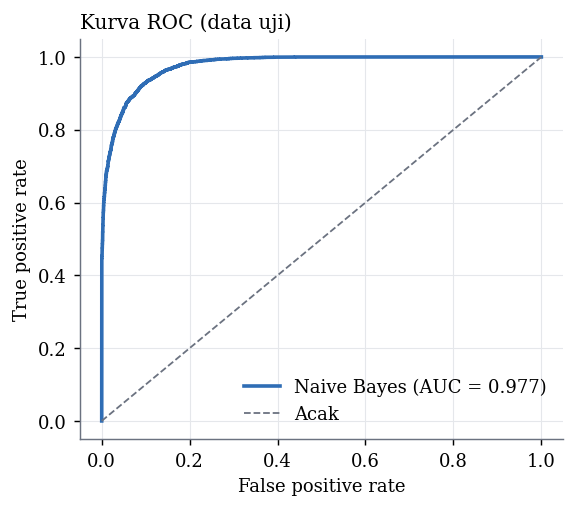

In [16]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(4.8, 4.0))
ax.plot(fpr, tpr, color=BIRU, lw=2, label=f"Naive Bayes (AUC = {hasil['auc']:.3f})")
ax.plot([0, 1], [0, 1], color=ABU, lw=1, ls="--", label="Acak")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Kurva ROC (data uji)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")
fig.savefig(f"{FIG_DIR}/05_roc.png"); plt.show()

In [17]:
# Validasi silang 5-fold pada seluruh data (stabilitas & pencegahan overfitting)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_acc = cross_val_score(GaussianNB(), X, y, cv=skf, scoring="accuracy")
cv_f1 = cross_val_score(GaussianNB(), X, y, cv=skf, scoring="f1")
print("Akurasi tiap fold:", cv_acc.round(4))
print(f"Akurasi CV: {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"F1 CV     : {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")

Akurasi tiap fold: [0.9114 0.914  0.9159 0.9133 0.9137]
Akurasi CV: 0.9137 ± 0.0014
F1 CV     : 0.9157 ± 0.0015


In [18]:
selisih = hasil["acc_train"] - hasil["acc_test"]
ringkasan = {
    **{k: round(float(v), 4) for k, v in hasil.items()},
    "selisih_train_test": round(float(selisih), 4),
    "cv_acc_mean": round(float(cv_acc.mean()), 4), "cv_acc_std": round(float(cv_acc.std()), 4),
    "cv_f1_mean": round(float(cv_f1.mean()), 4), "cv_f1_std": round(float(cv_f1.std()), 4),
    "n_total": int(len(df)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "n_dup": n_dup, "n_missing": n_missing, "baris_outlier": int(baris_outlier),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    "n_rendah": int(distribusi["Rendah"]), "n_tinggi": int(distribusi["Tinggi"]),
    "max_kor_antarfitur": round(float(kor.max()), 4),
}
with open("hasil.json", "w") as f:
    json.dump(ringkasan, f, indent=2)

print(f"Akurasi latih {hasil['acc_train']:.2%} vs uji {hasil['acc_test']:.2%} "
      f"(selisih {selisih:.2%}) -> {'tidak ada indikasi overfitting' if abs(selisih) < 0.02 else 'perlu diperiksa overfitting'}.")
print(f"Dari {tp+fn} wilayah berisiko Tinggi pada data uji, model menandai {tp} dengan benar "
      f"(recall {hasil['recall']:.2%}); {fn} terlewat.")

Akurasi latih 91.39% vs uji 91.49% (selisih -0.10%) -> tidak ada indikasi overfitting.
Dari 5103 wilayah berisiko Tinggi pada data uji, model menandai 4686 dengan benar (recall 91.83%); 417 terlewat.
